In [2]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Configuration
n_users = 200
n_records = 1000

# Generate 200 unique User IDs and their profile characteristics
user_ids = [f"USR_{1000 + i}" for i in range(n_users)]
user_profiles = {
    uid: {
        "Credit_Score": np.random.randint(580, 850),
        "Annual_Income": np.random.randint(30000, 150000)
    }
    for uid in user_ids
}

# Generate 1000 loan records
data = []
for _ in range(n_records):
    uid = np.random.choice(user_ids)
    profile = user_profiles[uid]

    # Generate loan details
    loan_amount = np.random.randint(5000, 50000)
    loan_term_months = np.random.choice([12, 24, 36, 48, 60])

    # Logic for approval probability based on Credit Score and Income
    # Better credit score and higher income -> higher chance of approval
    approval_prob = (profile["Credit_Score"] - 550) / 300 * 0.6 + (profile["Annual_Income"] / 150000) * 0.4
    approval_prob = np.clip(approval_prob, 0.05, 0.95)

    loan_status = np.random.choice(["Approved", "Rejected"], p=[approval_prob, 1 - approval_prob])

    data.append({
        "User_ID": uid,
        "Credit_Score": profile["Credit_Score"],
        "Annual_Income": profile["Annual_Income"],
        "Loan_Amount": loan_amount,
        "Loan_Term_Months": loan_term_months,
        "Interest_Rate_Pct": round(np.random.uniform(5.0, 18.0), 2),
        "Loan_Status": loan_status
    })

# Create DataFrame
df = pd.DataFrame(data)

# Show info and first few rows
print(f"Dataset shape: {df.shape}")
print(f"Unique users: {df['User_ID'].nunique()}")
print(df.head(10))

Dataset shape: (1000, 7)
Unique users: 199
    User_ID  Credit_Score  Annual_Income  Loan_Amount  Loan_Term_Months  \
0  USR_1144           755         100091        13311                36   
1  USR_1116           726          41411        10949                12   
2  USR_1121           678          46646        21896                24   
3  USR_1088           777          51959         8343                60   
4  USR_1021           714         126276        13130                48   
5  USR_1085           810          53776        24128                60   
6  USR_1093           812         148451        35445                48   
7  USR_1175           605         134290        34222                48   
8  USR_1022           746         117313        43649                24   
9  USR_1179           843          36655        45158                24   

   Interest_Rate_Pct Loan_Status  
0               6.02    Approved  
1               5.76    Rejected  
2               6.22    Ap

### Logistic Regression on Loan Status
Now, we will train a Logistic Regression model to predict whether a loan is approved or rejected based on the generated user features and loan details.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare features and target variable
# We will drop the 'User_ID' as it is a unique identifier
X = df.drop(columns=['User_ID', 'Loan_Status'])
y = df['Loan_Status'].map({'Approved': 1, 'Rejected': 0}) # Encode target

# Split train and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Scale the numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Train the Logistic Regression Model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# 4. Make Predictions
y_pred = model.predict(X_test_scaled)

# 5. Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

Accuracy Score: 71.50%

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.77      0.48      0.59        86
    Approved       0.69      0.89      0.78       114

    accuracy                           0.71       200
   macro avg       0.73      0.69      0.69       200
weighted avg       0.73      0.71      0.70       200



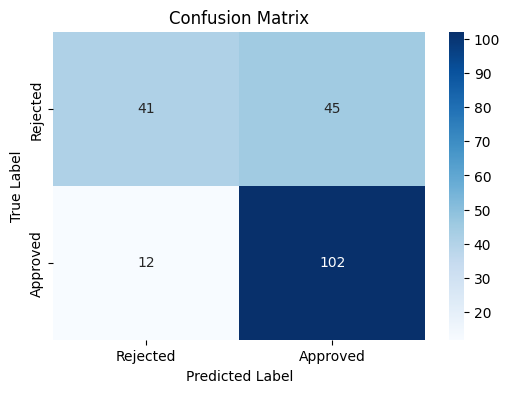

In [4]:
# 6. Visualize the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Rejected', 'Approved'], yticklabels=['Rejected', 'Approved'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Bias and Variance Analysis (Learning Curve)
We will plot the **Learning Curve** to analyze the model's bias and variance.
- A large gap between training and validation scores indicates **high variance** (overfitting).
- Low scores for both training and validation indicate **high bias** (underfitting).

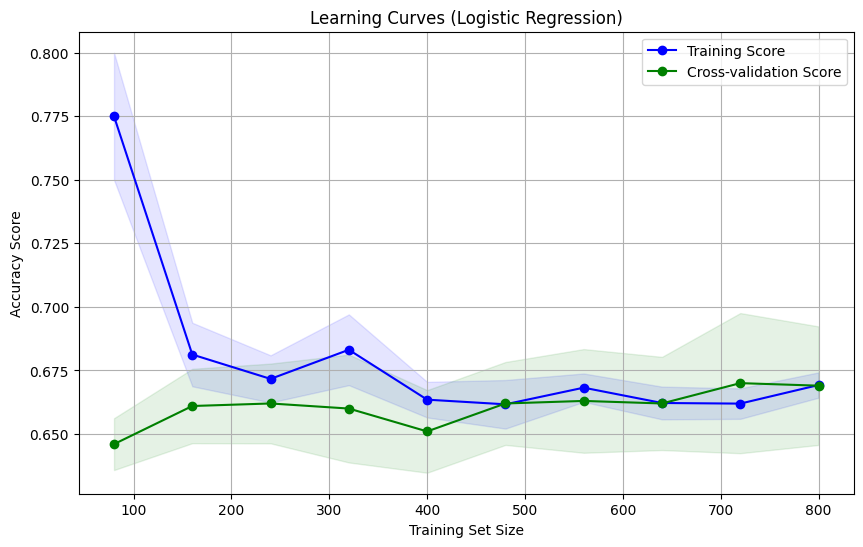

In [5]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(random_state=42),
    scaler.fit_transform(X), y,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Score')
plt.plot(train_sizes, test_mean, 'o-', color='green', label='Cross-validation Score')

plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color='green')

plt.title('Learning Curves (Logistic Regression)')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy Score')
plt.legend(loc='best')
plt.grid(True)
plt.show()

### Model Performance Curves (ROC and Precision-Recall)
Next, we plot the **ROC Curve** and the **Precision-Recall Curve** to assess model threshold-based performances.

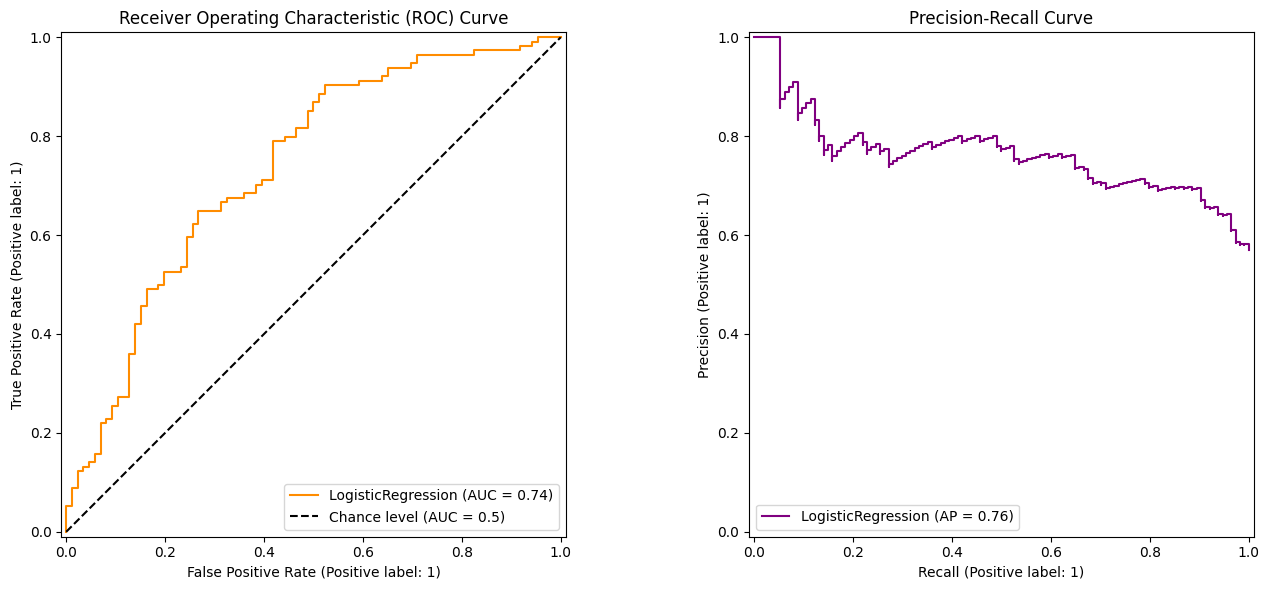

In [6]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

RocCurveDisplay.from_estimator(model, X_test_scaled, y_test, ax=ax1, color='darkorange')
ax1.plot([0, 1], [0, 1], 'k--', label='Chance level (AUC = 0.5)')
ax1.set_title('Receiver Operating Characteristic (ROC) Curve')
ax1.legend()

PrecisionRecallDisplay.from_estimator(model, X_test_scaled, y_test, ax=ax2, color='purple')
ax2.set_title('Precision-Recall Curve')

plt.tight_layout()
plt.show()

### Target Distribution: Actual vs Predicted (Pie Charts)
We can visualize the distribution of approved and rejected loans in the test dataset to see how well our model's predictions match the actual proportions.

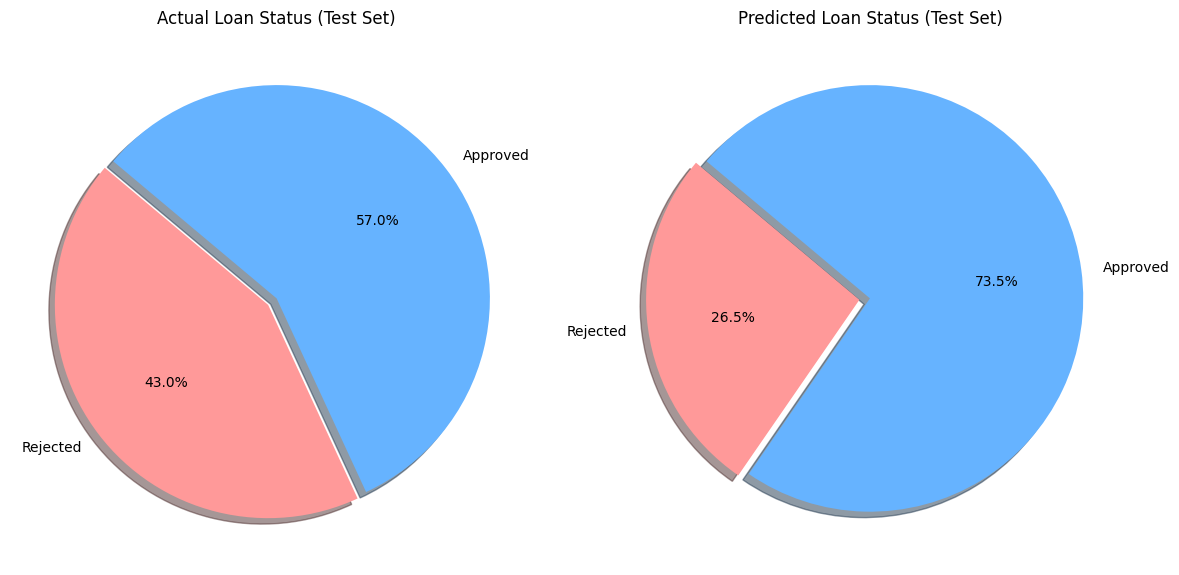

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Count actual values
actual_counts = np.bincount(y_test)
# Count predicted values
predicted_counts = np.bincount(y_pred)

labels = ['Rejected', 'Approved']
colors = ['#ff9999','#66b3ff']
explode = (0.05, 0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# Actual distribution
ax1.pie(actual_counts, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
ax1.set_title('Actual Loan Status (Test Set)')

# Predicted distribution
ax2.pie(predicted_counts, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
ax2.set_title('Predicted Loan Status (Test Set)')

plt.tight_layout()
plt.show()

### Custom Data Input & Model Testing
Use the form below to input custom features and test the trained Logistic Regression model's predictions in real-time.

In [28]:
#@title Loan Approval Prediction Test { run: "auto" }

# Interactive input parameters
Credit_Score = 730 #@param {type:"slider", min:580, max:850, step:10}
Annual_Income = 100000 #@param {type:"integer"}
Loan_Amount = 30000 #@param {type:"integer"}
Loan_Term_Months = 36 #@param [12, 24, 36, 48, 60] {type:"raw"}
Interest_Rate_Pct = 8.5 #@param {type:"number"}

# 1. Package the custom inputs into a DataFrame
custom_data = pd.DataFrame([{
    'Credit_Score': Credit_Score,
    'Annual_Income': Annual_Income,
    'Loan_Amount': Loan_Amount,
    'Loan_Term_Months': Loan_Term_Months,
    'Interest_Rate_Pct': Interest_Rate_Pct
}])

# 2. Scale the input data using the already fitted scaler
custom_scaled = scaler.transform(custom_data)

# 3. Predict probability and class
pred_prob = model.predict_proba(custom_scaled)[0]
pred_class = model.predict(custom_scaled)[0]

# 4. Display results beautifully
status = "Approved" if pred_class == 1 else "Rejected"
color = "green" if pred_class == 1 else "red"

print("=" * 40)
print("             PREDICTION RESULT              ")
print("=" * 40)
print(f"Credit Score:      {Credit_Score}")
print(f"Annual Income:     ${Annual_Income:,}")
print(f"Loan Amount:       ${Loan_Amount:,}")
print(f"Term (Months):     {Loan_Term_Months}")
print(f"Interest Rate:     {Interest_Rate_Pct}%")
print("-" * 40)
print(f"Approval Chance:   {pred_prob[1]:.2%}")
print(f"Rejection Chance:  {pred_prob[0]:.2%}")
print("-" * 40)
print(f"Model Prediction:  {status.upper()}")
print("=" * 40)

             PREDICTION RESULT              
Credit Score:      730
Annual Income:     $100,000
Loan Amount:       $30,000
Term (Months):     36
Interest Rate:     8.5%
----------------------------------------
Approval Chance:   63.23%
Rejection Chance:  36.77%
----------------------------------------
Model Prediction:  APPROVED
